# Visuo-Motor Neuron numbers

In [1]:
import numpy as np
import os
import json
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import re
from nested_dict import nested_dict
from collections import defaultdict



/tmp/ipykernel_14528/4271177305.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Extraction of Neuron numbers for visual areas

Data used:
    
   1. processed overlap data
   2. The realistic neuron numbers for the visual areas in FV91 parcellation from Visual multi area model

In [3]:
""" Data import """

basepath = os.path.abspath(os.path.join(os.path.dirname(''), '..'))
datapath = os.path.join(basepath, 'raw_data')
out_label = ''
out_path = basepath

FV91_visual_areas =  ['V1', 'V2', 'VP', 'V3', 'PIP', 'V3A', 'MT', 'V4t', 'V4',
                 'PO', 'VOT', 'DP', 'MIP', 'MDP', 'MSTd', 'VIP', 'LIP',
                 'PITv', 'PITd', 'AITv', 'MSTl', 'FST', 'CITv', 'CITd',
                 '7a', 'STPp', 'STPa', 'FEF', '46', 'TF', 'TH', 'AITd']


M132_visual_areas = ['V1_M132', 'V3_M132', 'V4_M132', 'PO_M132', 'V3A_M132', 'MT_M132', 
                     'DP_M132', 'V4t_M132', 'FST_M132', 'MST_M132', 'V6_M132', 'V2_M132', 
                     'V6A_M132', 'TEO_M132', 'TEpd_M132', 'TEam-p_M132', 'TEOm_M132', 'STPi_M132', 
                     'STPc_M132', 'PIP_M132', 'PGa_M132', 'TEpv_M132', '8l_M132', 'IPa_M132', 
                     '9_46d_M132', '8m_M132', 'TH_TF_M132', '46v_M132', 'LIP_M132', '8r_M132',
                     '46d_M132', '7A_M132', 'TEad_M132', '45B_M132', '9_46v_M132', 'VIP_M132', 
                     'TEam-a_M132', 'PBr_M132', 'PBc_M132', 'STPr_M132']

M132_visuomotor_areas = ['V1_M132', 'V3_M132', 'V4_M132', 'PO_M132', 'V3A_M132', 'MT_M132', 
                     'DP_M132', 'V4t_M132', 'FST_M132', 'MST_M132', 'V6_M132', 'V2_M132', 
                     'V6A_M132', 'TEO_M132', 'TEpd_M132', 'TEam-p_M132', 'TEOm_M132', 'STPi_M132', 
                     'STPc_M132', 'PIP_M132', 'PGa_M132', 'TEpv_M132', '8l_M132', 'IPa_M132', 
                     '9_46d_M132', '8m_M132', 'TH_TF_M132', '46v_M132', 'LIP_M132', '8r_M132',
                     '46d_M132', '7A_M132', 'TEad_M132', '45B_M132', '9_46v_M132', 'VIP_M132', 
                     'TEam-a_M132', 'PBr_M132', 'PBc_M132', 'STPr_M132', 'F1_M132', 'F2_M132', 'F3_M132', 
                     'F4_M132', 'F5_M132', 'F6_M132', 'F7_M132']

# Load M132 processed visual area data.
with open(os.path.join(datapath, 'overlap_data.json'), 'r') as f:
    overlap_data = json.load(f)

# Load Neuron number data for all of FV91 Areas
with open(os.path.join(datapath, 'viscortex_processed_data_backup.json'), 'r') as f:
    FV91_processed_data = json.load(f)
    
#FV91_processed_data['realistic_neuronal_numbers']



In [4]:

def calculate_m132_visual_neuron_numbers(overlap_data, neuron_data, fve_visual_areas):
    """
    Simplified calculation of M132 neuron numbers
    """
    m132_results = {}
    layers = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I', 'total']
    
    for m132_area, fve_overlaps in overlap_data.items():
        area_neurons = {layer: 0.0 for layer in layers}
        area = re.sub("_M132","", m132_area)
        for fve_full_name, percentage in fve_overlaps.items():
            # Extract base area name
            fve_base = fve_full_name.split('.', 1)[1] if '.' in fve_full_name else fve_full_name
            
            if fve_base in fve_visual_areas and fve_base in neuron_data:
                fraction = percentage / 100.0
                for layer in layers:
                    if layer in neuron_data[fve_base]:
                        area_neurons[layer] += neuron_data[fve_base][layer] * fraction
        
        m132_results[area] = area_neurons
    
    return m132_results


# Simple usage
neuron_numbers = FV91_processed_data['realistic_neuronal_numbers']
visual_neuron_numbers = calculate_m132_visual_neuron_numbers(overlap_data['overlap'], neuron_numbers, FV91_visual_areas)

# Save simple results
#with open('m132_visual_neuron_numbers.json', 'w') as f:
#    json.dump(simple_results, f, indent=2)



## Analysis of Neuron number data for motor related areas

Data used:
    
   1. Neuronal densities : [Cozzi et al 2017, Fig 3b](https://link.springer.com/article/10.1007/s00429-017-1369-3?utm_source=researchgate.net&utm_medium=article)
     
      - Below there are two neuron density arrays n2d_cozzi  and n2d_cozzi_2. The earlier one is the wrongly calculated neuronal densities
      - Difference the new calculations shows that L4 and L5 has nearly same neuron densities, which needs to be verified later.

   2. Laminar thicknesses : [Cozzi et al 2017, Fig 3d](https://link.springer.com/article/10.1007/s00429-017-1369-3?utm_source=researchgate.net&utm_medium=article)
   3. Reference total neuronal densities : [Beul et al 2017](https://www.nature.com/articles/srep43176) (Personal communication)

In [6]:
# --- Inputs ---
layers = ["L1","L2/3","L4","L5","L6"]

# Cozzi: 2D counts per 10k µm^2 (likely areal counts); layer thicknesses (µm -> mm)
n2d_cozzi = np.array([0.0, 20.9617, 14.71788, 39.29138, 27.72522])  # per 10,000 µm^2 (Cozzi)
n2d_cozzi_2 = np.array([0.0, 6.987234122, 4.915459982, 4.908704915, 5.545043654])


thickness_cozzi_um = np.array([56.78228872, 357.9258, 323.3743333, 1192.275149, 693.6388369])
thickness_cozzi_mm = thickness_cozzi_um / 1000.0


# Helper nested dict
#def nested_dict():
#    return defaultdict(nested_dict)


# Excitatory fraction per layer (use Binzegger/Potjans defaults for L2/3,L4,L5,L6)
# L1 has very few somata; choose a small excitatory fraction for L1 (adjustable).
gamma = {
    "L1": 0.20,     # small E fraction (placeholder)
    "L2/3": 0.78,
    "L4": 0.80,
    "L5": 0.82,
    "L6": 0.83
}

# Populations
populations = ["23E","23I","4E","4I", "5E","5I", "6E", "6I"]


# Motor areas data from Beul et al 2017 (Personal communication by Aitor):
motor_data = {
    "F1": {"density": 21400, "thickness": 2.364, "surface": 410.05299217904053},
    "F2": {"density": 26900, "thickness": 2.496, "surface": 194.37833884701158},
    "F3": {"density": 29000, "thickness": 2.280, "surface": 72.82582136540708},
    "F4": {"density": 22700, "thickness": 2.640, "surface": 60.381964244611076},
    "F5": {"density": 30000, "thickness": 2.424, "surface": 141.41573710028518},
    "F6": {"density": 28900, "thickness": 2.181, "surface": 40.17712759840639},
    "F7": {"density": 26000, "thickness": 2.319, "surface": 58.13174960306458}
}




def compute_motor_neuron_numbers(density_data):
    
    # Prepare results containers
    area_names = list(motor_data.keys())
    
    data = nested_dict()

    # For each area, compute scaling to Beul and per-layer densities and E/I counts
    for area in area_names:
        # --- Convert Cozzi 2D -> neurons per mm^2 (areal) ---
        density_per_layer_2d = 100.0 * density_data  # multiply by 100 to go from per 10k µm^2 to per mm^2

        # neurons per layer
        neurons_per_layer = (density_per_layer_2d) * motor_data['F1']['surface']

        # Raw total neurons per mm^2 from Cozzi (sum over layers)
        N_cozzi_total = neurons_per_layer.sum()

        D_A = motor_data[area]["thickness"]
        density = motor_data[area]["density"]
        surface = motor_data[area]["surface"]

        # target area total neurons per mm^2 using Beul anchor
        N_area = density * D_A * surface

        # compute scaling factor alpha
        alpha_A = N_area/ N_cozzi_total

        # scaled per-layer neurons per mm^2
        N_layer_scaled = neurons_per_layer * alpha_A  # neurons per mm^2 in each layer

        # excitatory / inhibitory counts per mm^2 (in the column)
        N_layer_E = np.array([N_layer_scaled[i] * gamma[layers[i]] for i in range(len(layers))])
        N_layer_I = N_layer_scaled - N_layer_E


         # --- Store results ---
        #data["realistic_neuron_numbers"][area]["alpha"] = alpha_A

        for i, layer in enumerate(layers):
            if layer == "L1":
                continue  # skip if L1 neuron count is 0
            if layer == "L2/3":
                data["realistic_neuron_numbers"][area]["23E"] = N_layer_E[i]
                data["realistic_neuron_numbers"][area]["23I"] = N_layer_I[i]
            elif layer == "L4":
                data["realistic_neuron_numbers"][area]["4E"] = N_layer_E[i]
                data["realistic_neuron_numbers"][area]["4I"] = N_layer_I[i]
            elif layer == "L5":
                data["realistic_neuron_numbers"][area]["5E"] = N_layer_E[i]
                data["realistic_neuron_numbers"][area]["5I"] = N_layer_I[i]
            elif layer == "L6":
                data["realistic_neuron_numbers"][area]["6E"] = N_layer_E[i]
                data["realistic_neuron_numbers"][area]["6I"] = N_layer_I[i]

        data["realistic_neuron_numbers"][area]["total"] = N_area
        data["Thickness_cozzi_mm"][area] = D_A
        data["Surface_area"][area] = surface
    
    return data



In [7]:
neuron_data_method_1 = compute_motor_neuron_numbers(n2d_cozzi)     # With initial Values of neuronal densities
neuron_data_method_2 = compute_motor_neuron_numbers(n2d_cozzi_2)   # With Updated neuronal densities

In [10]:
neuron_data_method_1

nested_dict(nested_dict.implementation.nested_dict,
            {'realistic_neuron_numbers': nested_dict(nested_dict.implementation.nested_dict,
                         {'F1': nested_dict(nested_dict.implementation.nested_dict,
                                      {'23E': 3302691.778266489,
                                       '23I': 931528.4502802915,
                                       '4E': 2378385.158353534,
                                       '4I': 594596.2895883834,
                                       '5E': 6508157.827031446,
                                       '5I': 1428620.0108117815,
                                       '6E': 4648362.9912113575,
                                       '6I': 952074.3475975068,
                                       'total': 20744416.85314079}),
                          'F2': nested_dict(nested_dict.implementation.nested_dict,
                                      {'23E': 2077837.317251201,
                                     

In [14]:
# Combine the dictionaries
combined_neuron_numbers_1 = {
    **visual_neuron_numbers,
    **neuron_data_method_1['realistic_neuron_numbers']
}


# Combine the dictionaries
combined_neuron_numbers_2 = {
    **visual_neuron_numbers,
    **neuron_data_method_2['realistic_neuron_numbers']
}

# Save the data of processed neuron numbers as 'm132_neuron_numbers_visuomotor_data_2.json'. 
# Earlier neuronal number with initial neuronal densities are saved in 'm132_neuron_numbers_visuomotor_data.json'
# These files are directly used in the 'visuomotor_mam_data_processing.ipynb' Notebook
# You just have to change the name of the file from 'm132_neuron_numbers_visuomotor_data.json' to 'm132_neuron_numbers_visuomotor_data_2.json'

save_data_path_method_1 = os.path.join(datapath, "m132_neuron_numbers_visuomotor_data.json")

with open(save_data_path_method_1, "w") as f:
    json.dump(combined_neuron_numbers_1, f, indent=4)



save_data_path_method_2 = os.path.join(datapath, "m132_neuron_numbers_visuomotor_data_2.json")

with open(save_data_path_method_2, "w") as f:
    json.dump(combined_neuron_numbers_2, f, indent=4)


## Analysis of difference in the values of neuronal numbers (in Method 1 and Method 2)

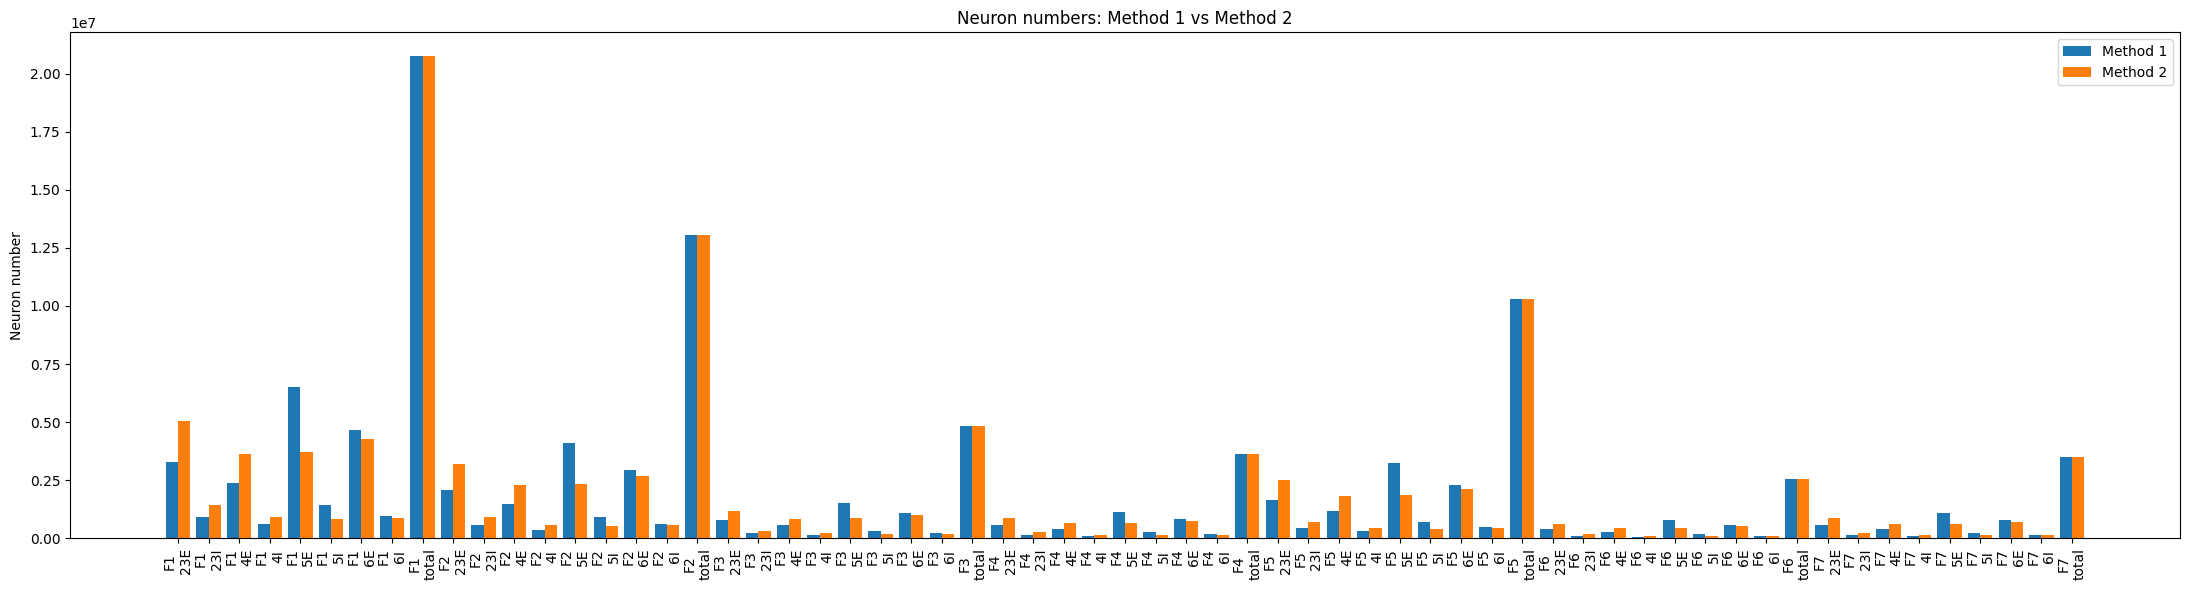

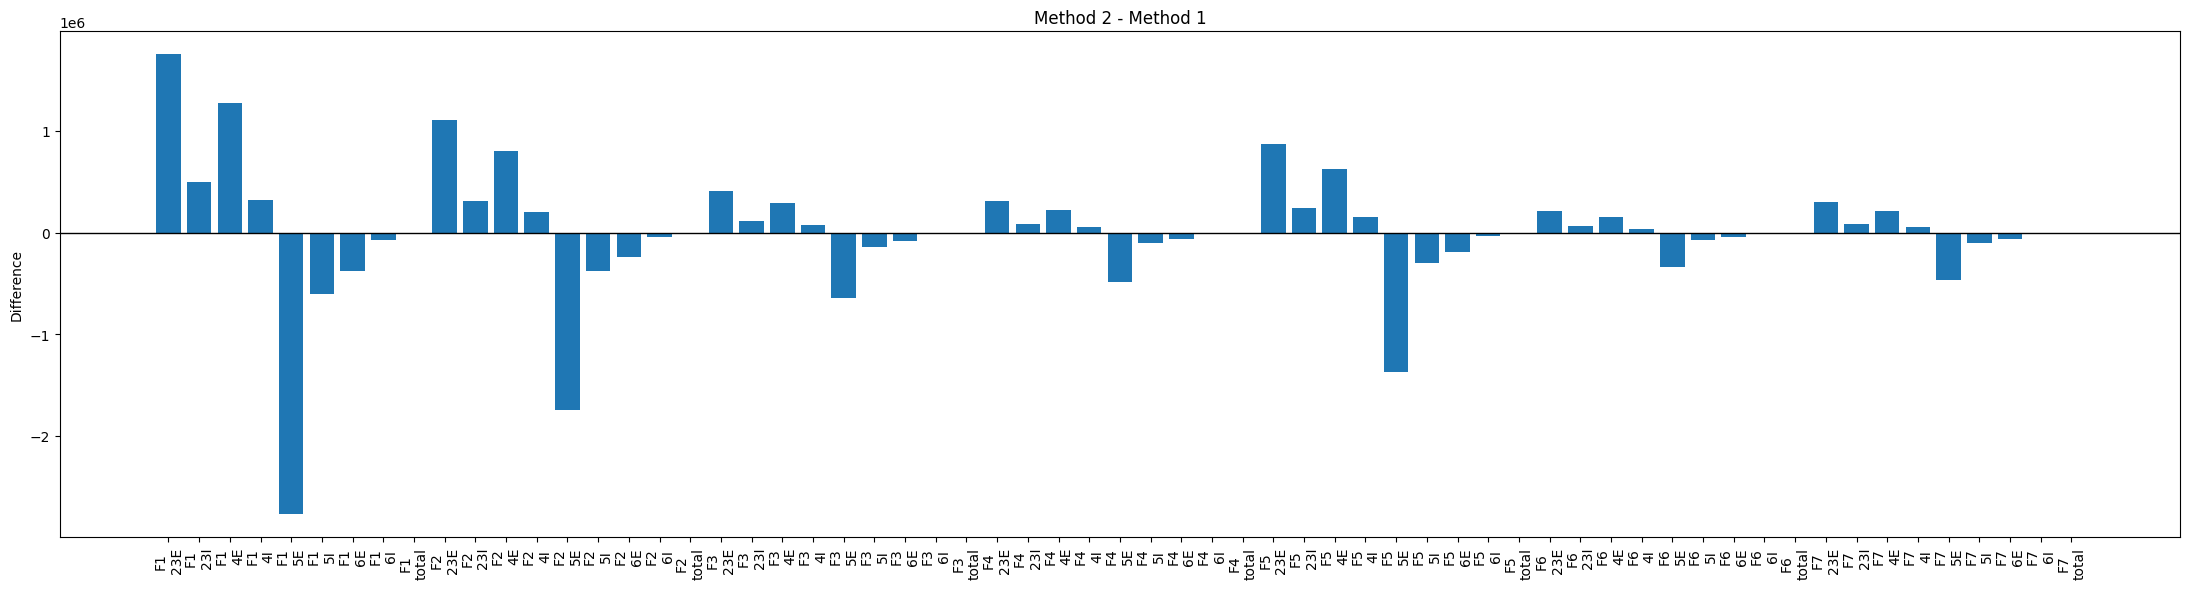

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Area and population lists
area_list = ["F1", "F2", "F3", "F4", "F5", "F6", "F7"]
population_list = ["23E", "23I", "4E", "4I", "5E", "5I", "6E", "6I", "total"]

labels = []
method1_values = []
method2_values = []
abs_diff = []
percent_diff = []

for area in area_list:
    for pop in population_list:
        v1 = neuron_data_method_1['realistic_neuron_numbers'][area][pop]
        v2 = neuron_data_method_2['realistic_neuron_numbers'][area][pop]

        labels.append(f"{area}\n{pop}")
        method1_values.append(v1)
        method2_values.append(v2)

        diff = v2 - v1
        abs_diff.append(diff)

        if v1 != 0:
            percent_diff.append(100 * diff / v1)
        else:
            percent_diff.append(np.nan)

method1_values = np.array(method1_values)
method2_values = np.array(method2_values)
abs_diff = np.array(abs_diff)
percent_diff = np.array(percent_diff)

x = np.arange(len(labels))
width = 0.4

# ---------------------------------------------------
# Plot 1: Method comparison
# ---------------------------------------------------

plt.figure(figsize=(22,6))

plt.bar(x - width/2, method1_values, width,
        label='Method 1')

plt.bar(x + width/2, method2_values, width,
        label='Method 2')

plt.xticks(x, labels, rotation=90)
plt.ylabel("Neuron number")
plt.title("Neuron numbers: Method 1 vs Method 2")
plt.legend()
plt.tight_layout()

# ---------------------------------------------------
# Plot 2: Absolute difference
# ---------------------------------------------------

plt.figure(figsize=(22,6))

plt.bar(x, abs_diff)

plt.axhline(0, color='k', linewidth=1)

plt.xticks(x, labels, rotation=90)
plt.ylabel("Difference")
plt.title("Method 2 - Method 1")
plt.tight_layout()


plt.tight_layout()

plt.show()